# P2: DETERMINACIÓN DE TIPOS DE ESTRELLAS

## 1. EDA

Aunque en el enunciado no pide explícitamente hacer un EDA, nosotros consideramos de gran ayuda hacer un breve análisis exploratorio del dataset sobre el que se desarrollará la práctica.

### 1.1. Importar los datos.

In [1]:
import pandas as pd
df = pd.read_csv('stars_data.csv')

print("Datos importados correctamente:")
print(df.shape[0], "filas y", df.shape[1], "columnas")

Datos importados correctamente:
240 filas y 6 columnas


### 1.2. Información general del dataset

In [2]:
#Vemos la forma general del dataset
print("\n--- Información general ---")
df.info()

# Comprobamos si hay valores nulos
print("\n--- Valores nulos por columna ---")
print(df.isnull().sum())


--- Información general ---
<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Temperature     240 non-null    int64  
 1   L               240 non-null    float64
 2   R               240 non-null    float64
 3   A_M             240 non-null    float64
 4   Color           240 non-null    str    
 5   Spectral_Class  240 non-null    str    
dtypes: float64(3), int64(1), str(2)
memory usage: 11.4 KB

--- Valores nulos por columna ---
Temperature       0
L                 0
R                 0
A_M               0
Color             0
Spectral_Class    0
dtype: int64


Como podemos ver, solo hay dos variables categóricas, Color y Spectral_Class (el resto son numéricas), y no tenemos valores nulos, por lo que no hará falta hacer ninguna imputación de ningún tipo.

### 1.3. Análisis univariante
#### 1.3.1 Análisis de variables numéricas

,Temperature,L,R,A_M
count,240.000000,240.000000,240.000000,240.000000
mean,10497.462500,107188.361635,237.157781,4.382396
std,9552.425037,179432.244940,517.155763,10.532512
min,1939.000000,0.000080,0.008400,-11.920000
25%,3344.250000,0.000865,0.102750,-6.232500
50%,5776.000000,0.070500,0.762500,8.313000
75%,15055.500000,198050.000000,42.750000,13.697500
max,40000.000000,849420.000000,1948.500000,20.060000



--- Valores más comunes ---
Temperature: 3600
L: 200000.0
R: 0.11
A_M: 12.23


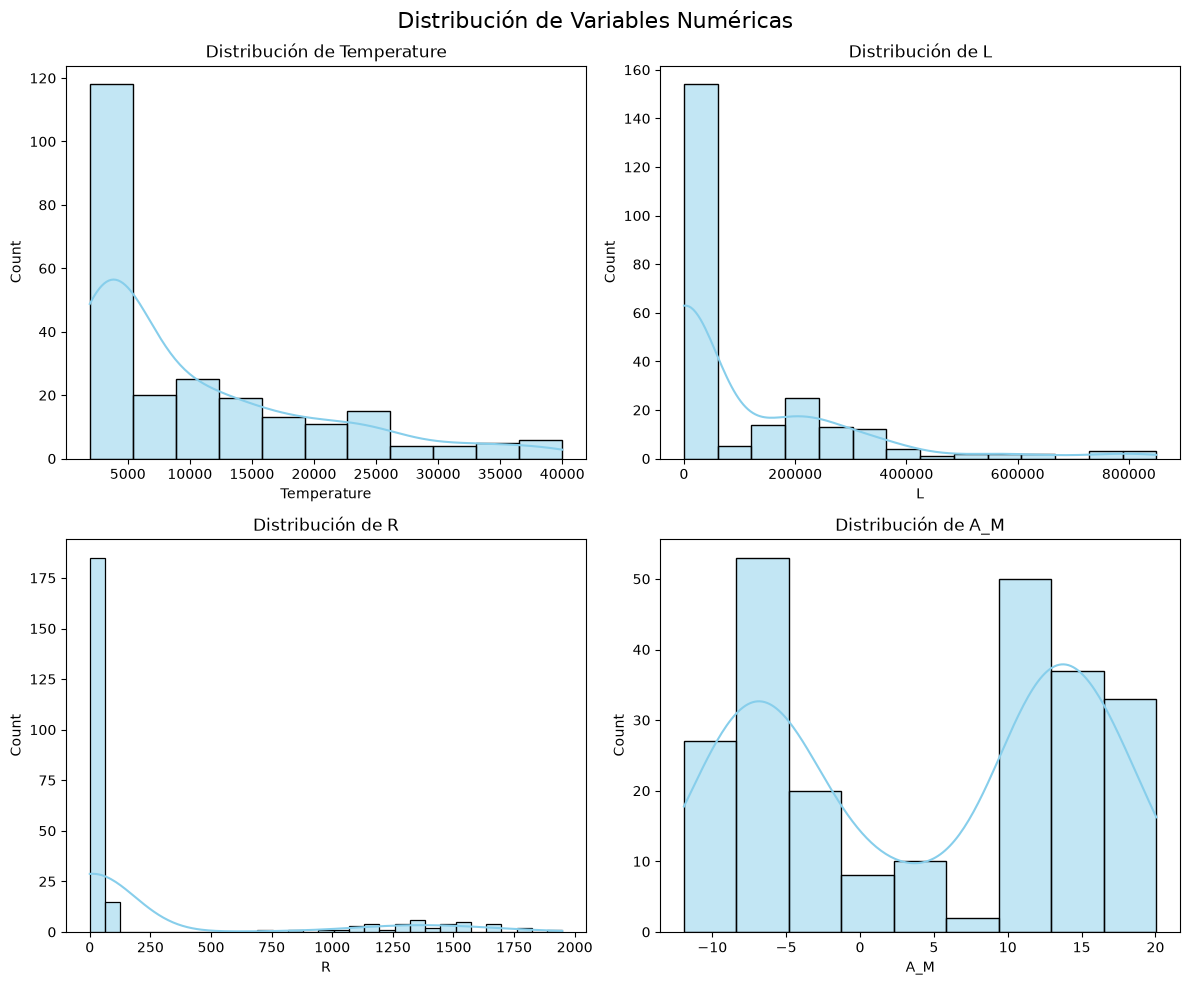

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Definimos cuáles son las columnas numéricas
num_cols = ['Temperature', 'L', 'R', 'A_M']

# describe() nos da el mínimo, máximo, media y cuartiles de un vistazo
display(df[num_cols].describe())

# Calculamos el valor que más se repite para cada variable
print("\n--- Valores más comunes ---")
for col in num_cols:
    moda = df[col].mode()[0]
    print(f"{col}: {moda}")

# Creamos una cuadrícula de 2x2 para las 4 variables
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Distribución de Variables Numéricas', fontsize=16)

for i, col in enumerate(num_cols):
    fila = i // 2
    columna = i % 2
    sns.histplot(data=df, x=col, kde=True, ax=axes[fila, columna], color='skyblue')
    axes[fila, columna].set_title(f'Distribución de {col}')

plt.tight_layout()
plt.show()

Con el anterior código nos podemos hacer una idea general de las variables numéricas del dataset. Podemos observar que en la mayoría de variables, los valores más comunes de estas están justo al principio, por lo que podremos sospechar que estos valores están relacionados entre sí y no son casuales.

Además, en la distribución de A_M, observamos una clara forma "bimodal" en la gráfica, por lo que nos hace pensar que dentro del dataset existen mínimo dos grupos de estrellas muy diferenciadas entre ellas.

#### 1.3.2. Análisis de variables categóricas

--- Valores de las variables ---

Valores para 'Color':
Color
Red                   112
Blue                   56
Blue-white             26
Blue White             10
yellow-white            8
White                   7
Blue white              4
Yellowish White         3
white                   3
Whitish                 2
Orange                  2
yellowish               2
Pale yellow orange      1
White-Yellow            1
Yellowish               1
Orange-Red              1
Blue-White              1
Name: count, dtype: int64

Valores para 'Spectral_Class':
Spectral_Class
M    111
B     46
O     40
A     19
F     17
K      6
G      1
Name: count, dtype: int64


C:\Users\ivang\AppData\Local\Temp\ipykernel_11244\1719873293.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='Color', order=df['Color'].value_counts().index, ax=axes[0], palette='viridis')
C:\Users\ivang\AppData\Local\Temp\ipykernel_11244\1719873293.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Spectral_Class', order=df['Spectral_Class'].value_counts().index, ax=axes[1], palette='magma')


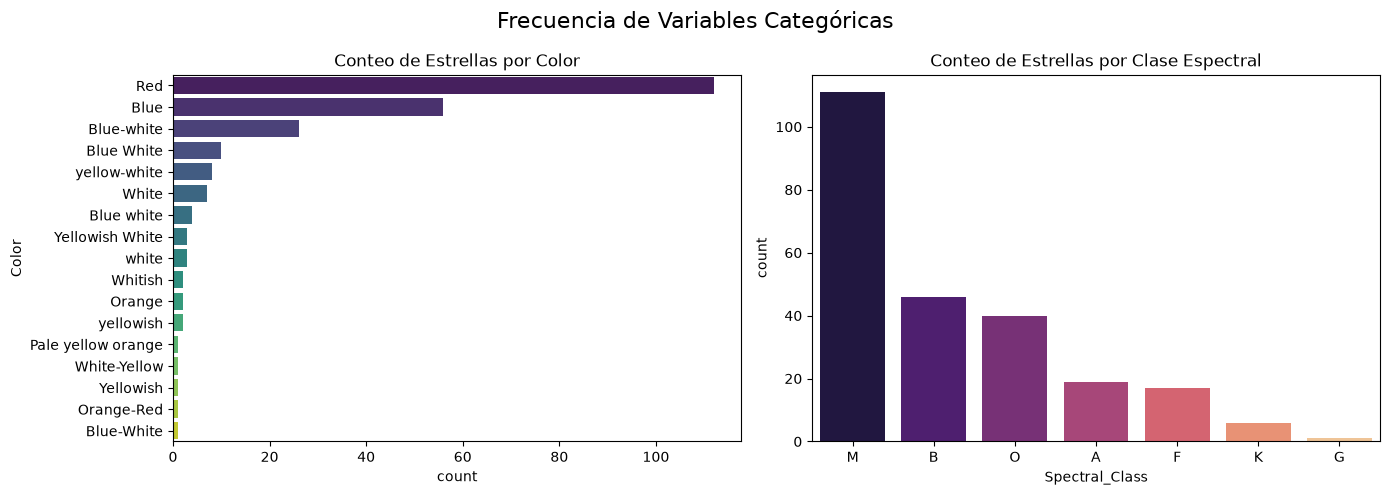

In [4]:
cat_cols = ['Color', 'Spectral_Class']

# imprimimos los valores de cada variable categórica
print("--- Valores de las variables ---")
for col in cat_cols:
    print(f"\nValores para '{col}':")
    print(df[col].value_counts())


fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Frecuencia de Variables Categóricas', fontsize=16)

# Gráfico para Color
sns.countplot(data=df, y='Color', order=df['Color'].value_counts().index, ax=axes[0], palette='viridis')
axes[0].set_title('Conteo de Estrellas por Color')

# Gráfico para Spectral_Class
sns.countplot(data=df, x='Spectral_Class', order=df['Spectral_Class'].value_counts().index, ax=axes[1], palette='magma')
axes[1].set_title('Conteo de Estrellas por Clase Espectral')

plt.tight_layout()
plt.show()

Aquí observamos muchas cosas interesantes, sobre todo en la gráfica de la izquierda, ya que aparecen valores repetidos para Color, como por ejemplo 'Blue-White' o 'Yellow-white', que aparecen en numerosas ocasiones ('blue white' y 'White-yellow' por ejemplo). 

También encontramos valores como 'Whitish', o 'Yellowish', que son valores que representan que no son el color puro, pero están muy cerca de él. Por lo tanto, asumimos que a Color habrá que hacerle cierto tratamiento antes de codificarla de manera ordinal.  

### 1.4. Análisis multivariante

En esta parte trataremos de estudiar cómo se relacionan las variables entre sí, de forma que podamos extraer pistas que nos sean de utilidad en el futuro.

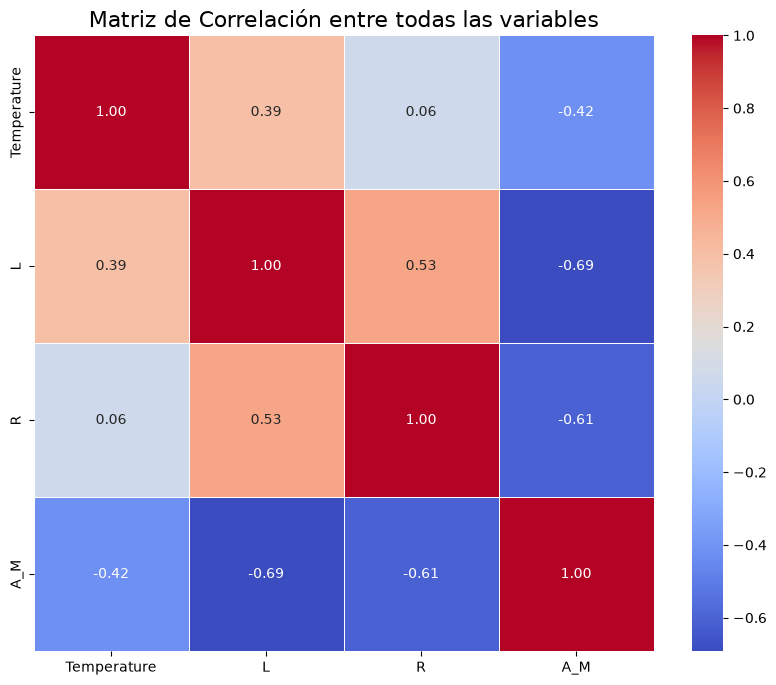

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculamos la matriz de correlación de las variables numericas del dataset
matriz_correlacion = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
# Pintamos el mapa de calor
sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Matriz de Correlación entre todas las variables', fontsize=16)
plt.show()

Al ver la gráfica en el que comparamos las variables numéricas entre sí, salta a la vista que la variable A_M tiene una correlación bastante baja con todas las demás, por lo que es bastante independiente. También vemos que tanto Temperature y L como L y R tienen una correlación alta entre ellas, mostrando que están relacionadas entre ellas.

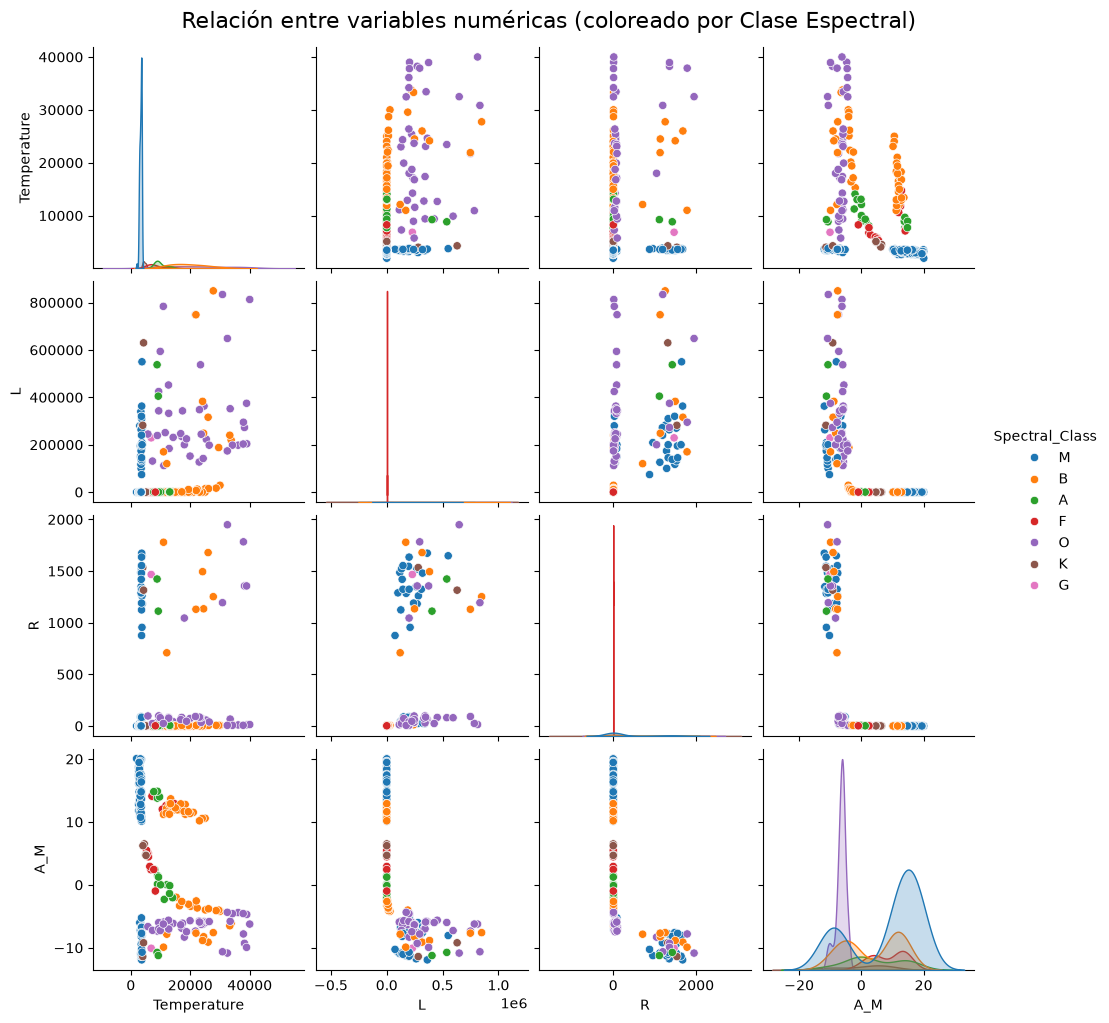

In [6]:
columnas_numericas = ['Temperature', 'L', 'R', 'A_M']

# Volvemos a cargar las categorías originales temporalmente para que la leyenda quede bonita en el gráfico
df_visual = pd.read_csv('stars_data.csv') 

sns.pairplot(df_visual, vars=columnas_numericas, hue='Spectral_Class', palette='tab10', diag_kind='kde')
plt.suptitle('Relación entre variables numéricas (coloreado por Clase Espectral)', y=1.02, fontsize=16)
plt.show()

Aquí observamos muchas cosas interesantes, sobre todo en las gráficas de la diagonal principal. Si nos fijamos en la de abajo a la derecha, la de la Magnitud Absoluta (A_M), vemos que aparecen dos grandes "montañas" o picos de datos claramente separados. Esto nos indica que no estamos ante un grupo uniforme, sino que existen al menos dos poblaciones de estrellas muy distintas.

También encontramos un comportamiento muy extremo en las gráficas de Luminosidad (L) y Radio (R), ya que casi todos los puntos están apelotonados muy cerca del cero y solo unos pocos tienen valores gigantescos. Son valores que representan a estrellas supergigantes que distorsionan por completo la escala. Por lo tanto, asumimos que a estas variables numéricas habrá que hacerles cierto tratamiento de estandarización (como un StandardScaler) antes de pasárselas a los algoritmos.

Por último, en cruces de variables como el de Temperatura frente a A_M (esquina inferior izquierda), observamos que los puntos de un mismo color ya se juntan formando "islas" muy evidentes. Esto representa que las variables guardan una fuerte relación física entre ellas.

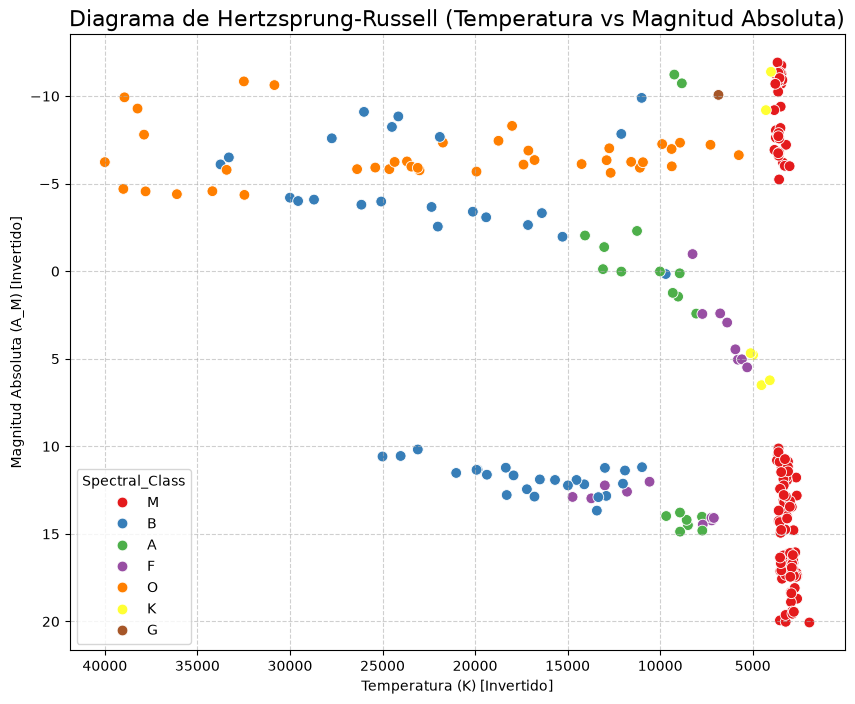

In [7]:
plt.figure(figsize=(10, 8))

# Pintamos Temperatura (eje X) vs Magnitud Absoluta (eje Y)
sns.scatterplot(data=df_visual, x='Temperature', y='A_M', hue='Spectral_Class', palette='Set1', s=60)

plt.gca().invert_xaxis()  # Temperatura de mayor a menor
plt.gca().invert_yaxis()  # Magnitud de mayor (menos brillante) a menor (más brillante)

plt.title('Diagrama de Hertzsprung-Russell (Temperatura vs Magnitud Absoluta)', fontsize=16)
plt.xlabel('Temperatura (K) [Invertido]')
plt.ylabel('Magnitud Absoluta (A_M) [Invertido]')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Aquí vemos muchas cosas, sobre todo en la forma en la que se distribuyen los datos en el gráfico. Si nos fijamos en la parte inferior central, vemos que aparece un grupo aislado de estrellas muy calientes pero con muy poco brillo. Esto nos indica que no estamos ante una nube de puntos uniforme, sino que existe una población muy particular y separada del resto (conocida en astronomía como enanas blancas).

También encontramos un comportamiento muy extremo en la zona derecha de la gráfica, la cual corresponde a las estrellas más frías (los puntos rojos de la Clase M), ya que estos puntos se dividen en dos bloques totalmente separados: unos arriba del todo (estrellas muy brillantes) y otros abajo del todo (estrellas muy tenues), sin haber prácticamente nada en la zona intermedia. Son valores que suponemos que representan a las gigantes rojas y a las enanas rojas, poblaciones que parten la escala en dos extremos. 

Por último, al analizar la imagen global, observamos que los puntos de un mismo color (las clases espectrales) ya se juntan formando "islas" muy evidentes a lo largo de todo el diagrama. Esto representa que las variables guardan una fuerte relación física entre ellas y que las agrupaciones ya existen de forma natural. 


### 1.5. Tratamiento de la variable Color & Spectral_Class

Tras hacer el eda, queda claro que hay que hacer tratamiento a las variables categóricas, de forma que pasen de variables categóricas a variables ordinales.

Respecto a Spectral_Class hemos optado por asignar el valor más frío al 0 (M = 0), y al 6 el más caliente, es decir, O = 6.

En cuanto a Color, hay varias cosas importantes a reseñar. Por una parte, unificamos las variables mal escritas (las que aparecen varias veces pero se refieren a lo mismo) en 'blue white' y 'yellow white'. Por otra, es importante hacer notar que hay valores que están muy cerca de las otras, como por ejemplo 'Whitish' de 'white' o 'yellowish' de 'yellow'. Al principio pensamos en incluir este tipo de valores en la escala final ordinal, asignándole valores con decimales (por ejemplo, 3.75 a 'yellowish white'), sin embargo, debido al reducido tamaño del dataset, optamos por generalizar estas variables al final, ya que habría muy pocas instancias de este tipo de variables para que el modelo pudiese generalizar correctamente.

In [8]:
import pandas as pd

df = pd.read_csv('stars_data.csv')

# Pasamos a minusculas y quitamos guiones
df['Color'] = df['Color'].str.lower().str.strip().str.replace('-', ' ')

# nos quitamos los valores raros
reemplazos_color = {
    'whitish': 'white',
    'yellowish': 'yellow',
    'pale yellow orange': 'orange',
    'orange red': 'orange',
    'white yellow': 'yellow white',
    'yellowish white': 'yellow white'
}
df['Color'] = df['Color'].replace(reemplazos_color)

# Transformamos el color 
color_ordinal_map = {
    'red': 0,
    'orange': 1,
    'yellow': 2,
    'yellow white': 3,
    'white': 4,
    'blue white': 5,
    'blue': 6
}

# guardamos las variables ordinales en una nueva columna
df['Color_Ordinal'] = df['Color'].map(color_ordinal_map)

# Transformación Ordinal para Spectral_Class
spectral_ordinal_map = {
    'M': 0, 
    'K': 1, 
    'G': 2, 
    'F': 3, 
    'A': 4, 
    'B': 5, 
    'O': 6  
}
df['Spectral_Class'] = df['Spectral_Class'].str.strip().str.upper()
df['Spectral_Class_Ordinal'] = df['Spectral_Class'].map(spectral_ordinal_map)

# Verificación de resultados
print("Nuevos colores únicos:", df['Color'].unique())
print("Nuevos valores ordinales de Color:", df['Color_Ordinal'].unique())

print("Nuevos valores ordinales de Spectral Class:", df['Spectral_Class_Ordinal'].unique())

# Eliminamos las columnas originales de texto
df = df.drop(columns=['Color', 'Spectral_Class'])

Nuevos colores únicos: <StringArray>
['red', 'blue white', 'white', 'yellow white', 'orange', 'blue', 'yellow']
Length: 7, dtype: str
Nuevos valores ordinales de Color: [0 5 4 3 1 6 2]
Nuevos valores ordinales de Spectral Class: [0 5 4 3 6 1 2]


Tras ejecutar este código, podemos observar que las variables categóricas pasan a ser numéricas ordinales de forma exitosa. Para ver cómo ha quedado la tabla, ejecutamos el siguiente código.

In [9]:
#Vemos la forma general del dataset
print("\n--- Información general ---")
df.info()


--- Información general ---
<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Temperature             240 non-null    int64  
 1   L                       240 non-null    float64
 2   R                       240 non-null    float64
 3   A_M                     240 non-null    float64
 4   Color_Ordinal           240 non-null    int64  
 5   Spectral_Class_Ordinal  240 non-null    int64  
dtypes: float64(3), int64(3)
memory usage: 11.4 KB


## 2. Escalado y PCA

Para hacer el PCA, hay que hacer previamente el escalado, ya que precisamente lo que hace PCA es encontrar las direcciones donde los datos tienen mayor varianza, por lo que si no estandarizásemos, variables como Temperature eclipsarían a variables como L.

In [10]:
# Estandarizamos el dataset

from sklearn.preprocessing import StandardScaler

std_scaler = StandardScaler()

# Aplicamos el escalador y lo guardamos directamente como un DataFrame de Pandas
df_scaled = pd.DataFrame(std_scaler.fit_transform(df), columns=df.columns)

# Comprobamos los resultados
resumen_escalado = df_scaled.describe().round(2)
print("Resumen estadístico tras el escalado:")
print(resumen_escalado)

Resumen estadístico tras el escalado:
       Temperature       L       R     A_M  Color_Ordinal  \
count       240.00  240.00  240.00  240.00         240.00   
mean         -0.00    0.00   -0.00   -0.00          -0.00   
std           1.00    1.00    1.00    1.00           1.00   
min          -0.90   -0.60   -0.46   -1.55          -1.00   
25%          -0.75   -0.60   -0.46   -1.01          -1.00   
50%          -0.50   -0.60   -0.46    0.37           0.13   
75%           0.48    0.51   -0.38    0.89           0.89   
max           3.09    4.15    3.32    1.49           1.27   

       Spectral_Class_Ordinal  
count                  240.00  
mean                    -0.00  
std                      1.00  
min                     -1.00  
25%                     -1.00  
50%                      0.19  
75%                      0.98  
max                      1.38  


Tras esto, generamos el PCA, lo haremos de dos dimensiones, de forma que obtengamos los dos componenetes más significativos del dataset.

In [11]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=100522281) 
datos_pca = pca.fit_transform(df_scaled)

Graficamos los resultados de forma visual

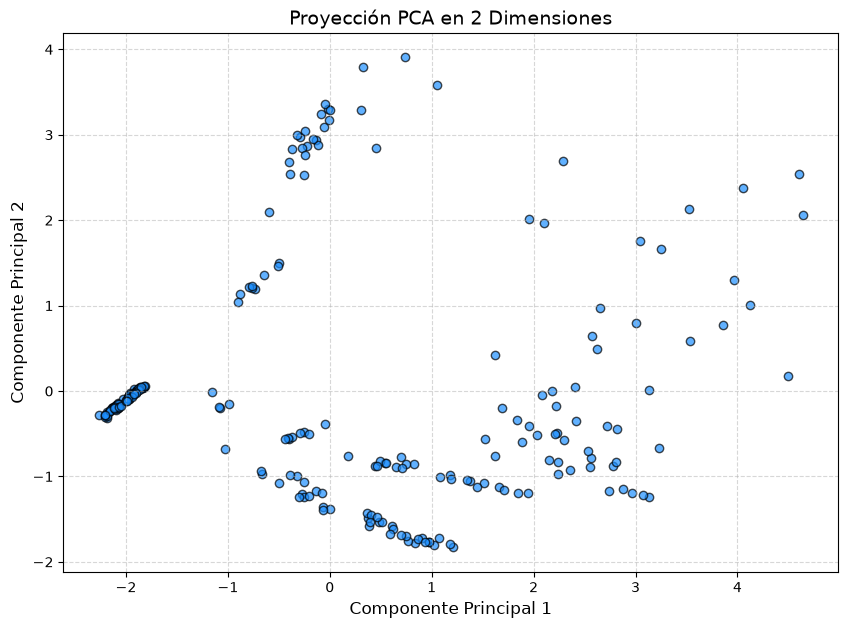

In [12]:
import matplotlib.pyplot as plt

# Crear la figura
plt.figure(figsize=(10, 7))

# Dibujar los puntos
plt.scatter(datos_pca[:, 0], datos_pca[:, 1], alpha=0.7, color='dodgerblue', edgecolors='k')

# Añadir títulos y etiquetas
plt.title('Proyección PCA en 2 Dimensiones', fontsize=14)
plt.xlabel('Componente Principal 1', fontsize=12)
plt.ylabel('Componente Principal 2', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

# Mostrar la gráfica
plt.show()

In [13]:
import pandas as pd
import numpy as np


# Vemos cuanto ha retenido en la varianza
varianza = pca.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza)

print("--- Varianza ---")
for i, var in enumerate(varianza):
    print(f"Componente {i+1}: {var*100:.2f}%")
print(f"Varianza total retenida: {varianza_acumulada[-1]*100:.2f}%\n")

# vamos las ecuaciones de cada componente
# pca.components_ contiene los multiplicadores de la ecuación lineal
pesos_pca = pd.DataFrame(
    pca.components_,
    columns=df_scaled.columns, # Usamos los nombres de las columnas originales
    index=[f'Componente {i+1}' for i in range(pca.n_components_)]
)

print("--- Pesos de los componentes ---")
print(pesos_pca.round(3))

--- Varianza ---
Componente 1: 55.77%
Componente 2: 29.57%
Varianza total retenida: 85.34%

--- Pesos de los componentes ---
              Temperature      L      R    A_M  Color_Ordinal  \
Componente 1        0.469  0.368  0.170 -0.399          0.472   
Componente 2       -0.218  0.405  0.637 -0.404         -0.343   

              Spectral_Class_Ordinal  
Componente 1                   0.483  
Componente 2                  -0.319  


Tras hacer el PCA, logramos retener un 85,34% de toda la información usando solo dos dimensiones. Si bien es verdad que "perdemos" en cierta forma casi un 15% de información, esto es asumible porque precisamente el algoritmo extrae las partes más importantes de cada variable del dataset, así que en realidad es muy poco probable que hubiese información valiosa en ese 15%. Además, al reducir la dimensionalidad, el entrenamiento de los tres modelos de la práctica, todos ellos basados en distancias, será mucho más rápido, ya que solo tendrán que hacer cálculos en dos dimensiones, en vez de en seis.

Además, si nos fijamos en los coeficientes de las variables Temperature, Color_Ordinal y Spectral_Class_Ordinal, nos damos cuenta de que son extremadamente parecidos en el componente 1. De esto podemos deducir que están fuertemente correlacionadas, o en otras palabras, al algoritmo le parecen muy similares porque para él aportan prácticamente la misma información.

## 3.1. K-Means

Tras hacer el PCA, ya estamos en disposición de empezar con los algoritmos de clustering de la práctica. Empezamos por entrenar el modelo K-Means, basado en proximidad y con el único hiperparámetro K, que especifica el número de centroides, y por extensión el número de conjuntos que van a haber. 

En cuanto al proceso de entrenamiento, hemos deducido que no hay que hacer ningún tipo de preprocesado, pues no hay variables con instancias nulas y ya estandarizamos todas las variables antes de hacer el PCA. De esta forma, podemos proceder directamente a probar el modelo con los distintos valores de K para encontrar el mejor mediante un simple bucle for de Python.

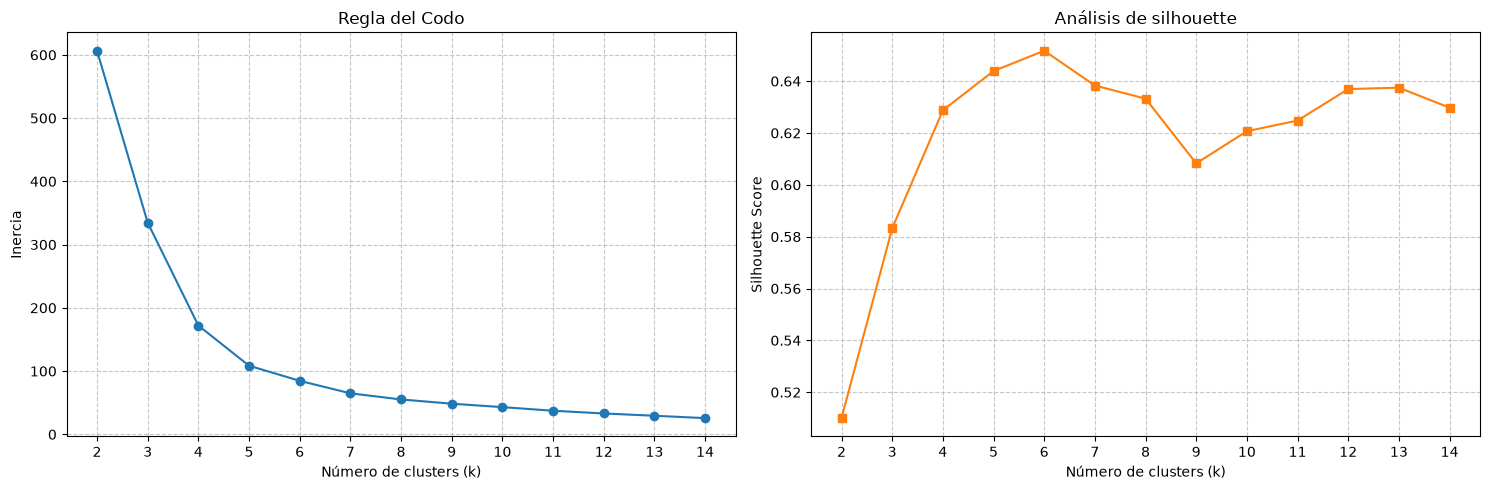

In [14]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Definimos el rango del hiperparametro k a evaluar
rango_k = range(2, 15)

# Listas para guardar las métricas de cada iteración
valores_inercia = []
valores_silueta = []

for k in rango_k:
    # Creamos el modelo. 
    # n_init=20 ejecuta el algoritmo 20 veces con distintos centroides iniciales
    kmeans = KMeans(n_clusters=k, random_state=100522281, n_init=20)
    
    # Entrenamos el modelo con los datos
    kmeans.fit(datos_pca)
    
    # Guardamos la inercia (lo del codo)
    valores_inercia.append(kmeans.inertia_)
    
    # Calculamos y guardamos el score de silhouette
    score_silueta = silhouette_score(datos_pca, kmeans.labels_)
    valores_silueta.append(score_silueta)

# Creación de las gráficas 
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Gráfica de la regla del codo 
ax1.plot(rango_k, valores_inercia, marker='o', linestyle='-', color='tab:blue')
ax1.set_title('Regla del Codo')
ax1.set_xlabel('Número de clusters (k)')
ax1.set_ylabel('Inercia')
ax1.set_xticks(rango_k)
ax1.grid(True, linestyle='--', alpha=0.7)

# gráfica de Análisis de silhouette
ax2.plot(rango_k, valores_silueta, marker='s', linestyle='-', color='tab:orange')
ax2.set_title('Análisis de silhouette')
ax2.set_xlabel('Número de clusters (k)')
ax2.set_ylabel('Silhouette Score')
ax2.set_xticks(rango_k)
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

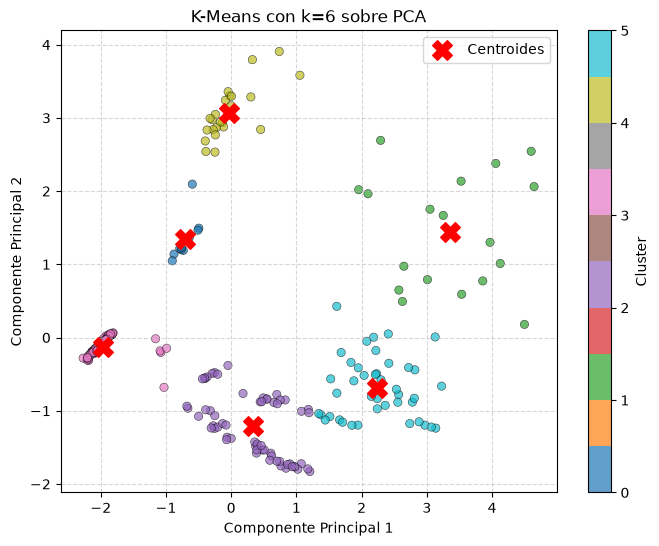

Silueta final (k=6): 0.6517
Inercia final (k=6): 84.60


In [15]:
# Modelo final con el k óptimo
kmeans_final = KMeans(n_clusters=6, random_state=100522281, n_init=20)
kmeans_final.fit(datos_pca)
labels = kmeans_final.labels_

# Visualización
plt.figure(figsize=(8, 6))
scatter = plt.scatter(datos_pca[:, 0], datos_pca[:, 1], 
                      c=labels, cmap='tab10', alpha=0.7, edgecolors='k', linewidths=0.4)
plt.scatter(kmeans_final.cluster_centers_[:, 0], kmeans_final.cluster_centers_[:, 1],
            c='red', marker='X', s=200, label='Centroides', zorder=5)
plt.title('K-Means con k=6 sobre PCA')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend()
plt.colorbar(scatter, label='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print(f"Silueta final (k=6): {silhouette_score(datos_pca, labels):.4f}")
print(f"Inercia final (k=6): {kmeans_final.inertia_:.2f}")

Tras ejecutar el bucle por completo hemos obtenido el valor más alto de Silhouette con k = 6, logrando casi un 0.66. En cuanto a la "Regla del codo", si bien es cierto que no se aprecia un vértice claro, es evidente que hay una estabilización a partir de k = 5 (algo que encaja con la otra gráfica ya que en ella k=5 obtiene un valor muy similar a k = 6).

Por ello, hemos decidido que el mejor valor de k para este problema en específico sea k = 6. Hemos entrenado de nuevo el modelo con el hiperparámetro elegido y hemos pintado la gráfica obtenida al hacer PCA para ver cómo se han distribuido los clusters. También hemos impreso por pantalla tanto la inercia (un 84.60) como el coeficiente de Silhouette, un 0.6517, un valor que consideramos bastante razonable y bueno para ser aprendizaje no supervisado.

## 3.2. Hierarchical Clustering

Continuamos probando los distintos modelos, y ahora nos centraremos en los algoritmos de jerarquía, concretamente entrenaremos el algoritmo AgglomerativeClustering de scikit-learn. 

Al estar basado en el concepto de jerarquías, tenemos los siguientes hiperparámetros del cluster:
- n_clusters: determina el número de clusters que se van a generar. Se puede dejar en None si se utiliza distance_treshold.
- distance_treshold: Es la altura del dendograma a partir de la cual se dejan de unir los clusters.
- affinity: Es la métrica que especifica qué tipo de distancia se usará. Puede ser: “euclidean”, “l1”, “l2”, “manhattan”, “cosine”, or “precomputed”. Si se utiliza linkage=“ward”, solo se permite “euclidean”.
- `linkage: Es la forma que tenemos de medir la distancia entre los clusters. Puede ser “ward”, “complete”, “average” o “single”.

Para elegir el mejor conjunto de hiperparámetros para este caso, ejecutamos el siguiente código.

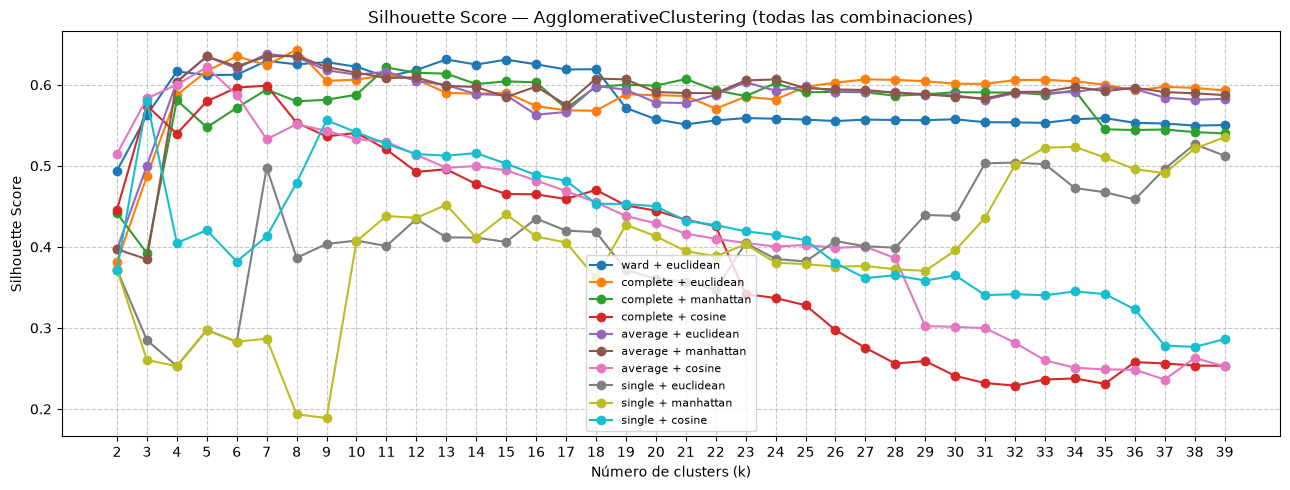

In [16]:
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

rango_clusters = range(2, 40)

# ward solo admite euclidean, el resto admiten más métricas
combinaciones = [
    ('ward',     'euclidean'),
    ('complete', 'euclidean'),
    ('complete', 'manhattan'),
    ('complete', 'cosine'),
    ('average',  'euclidean'),
    ('average',  'manhattan'),
    ('average',  'cosine'),
    ('single',   'euclidean'),
    ('single',   'manhattan'),
    ('single',   'cosine'),
]

resultados_silueta = {}

# Probamos con cada combinacion para obtener el mejor resultado
for linkage, affinity in combinaciones:
    scores = []
    for k in rango_clusters:
        # entrenamos el modelo
        modelo = AgglomerativeClustering(
            metric     = affinity,
            linkage    = linkage,
            n_clusters = k
        )
        etiquetas = modelo.fit_predict(datos_pca)
        scores.append(silhouette_score(datos_pca, etiquetas))
    # guardamos el resultado
    resultados_silueta[(linkage, affinity)] = scores

# Gráfica
fig, ax = plt.subplots(figsize=(13, 5))
for (linkage, affinity), scores in resultados_silueta.items():
    ax.plot(rango_clusters, scores, marker='o', label=f'{linkage} + {affinity}')
ax.set_title('Silhouette Score — AgglomerativeClustering (todas las combinaciones)')
ax.set_xlabel('Número de clusters (k)')
ax.set_ylabel('Silhouette Score')
ax.set_xticks(list(rango_clusters))
ax.legend(fontsize=8)
ax.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Tras analizar la gráfica obtenemos que la mejor combinación para este tipo de modelo es el de complete + euclidean con 8 clusters. Este resultado nos parece bastante curioso, ya que si comparamos este resultado con el dado por el modelo anterior, vemos que el número de clusters ha cambiado de seis a ocho, a pesar de trabajar ambos en el mismo dataset, y sobre todo por el hecho de que en el propio enunciado nos dan una tabla con seis grupos de estrellas. Suponemos que esto se debe a que utilizan una "filosofía" distinta a la hora de generar las agrupaciones, mientras k-means se basa en centroides, este se basa en jerarquías.

En cuanto a la combinación de complete + euclidean, podemos decir que a ojos del modelo el dataset presenta una estructura fuertemente compacta y segmentada, ya que "complete" penaliza mucho la fusión de grupos grandes o dispersos, y "euclidean" mide la distancia en línea recta, lo que matemáticamente favorece la creación de grupos con formas esféricas o redondeadas.Esta combinación significa que el algoritmo busca constantemente formar clústeres con el menor diámetro máximo posible en un espacio donde las diferencias absolutas entre las características (como temperatura y luminosidad) son críticas. Como resultado, el modelo se resiste a fusionar estructuras alargadas o muy extensas, forzando la división del espacio de datos en múltiples "burbujas" pequeñas, densas e independientes.

Para entrenar el modelo final y mostrar su coeficiente de silhouette tenemos el código de abajo.

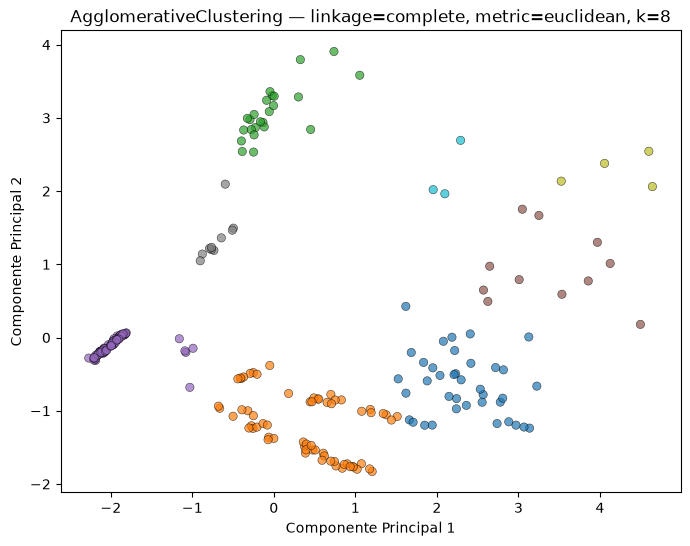

Silhouette final: 0.6432


In [17]:
# Modelo final con los mejores hiperparámetros
mejor_lnk = 'complete'       # el mejor link es complete
mejor_met = 'euclidean'  # el mejor affinity es euclideo
mejor_k   = 8            # el mejor parametro k es 8

# entrenamos el modelo final
modelo_hc_final = AgglomerativeClustering(
    metric     = mejor_met,
    linkage    = mejor_lnk,
    n_clusters = mejor_k
)
labels_hc = modelo_hc_final.fit_predict(datos_pca)

# Vemos como queda el grafico con los clusters del modelo
plt.figure(figsize=(8, 6))
scatter = plt.scatter(datos_pca[:, 0], datos_pca[:, 1],
                      c=labels_hc, cmap='tab10', alpha=0.7, edgecolors='k', linewidths=0.4)
plt.title(f'AgglomerativeClustering — linkage={mejor_lnk}, metric={mejor_met}, k={mejor_k}')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.show()

# para este metodo sigue siendo válido usar silhouette
print(f"Silhouette final: {silhouette_score(datos_pca, labels_hc):.4f}")

Tras ejecutar la celda, obtenemos el coeficiente de Silhouette del modelo final, que nos ha dado 0.6432. Este valor es menor que el obtenido por el modelo final de k-means, lo que nos hace sospechar que realmente el modelo anterior ha encontrado agrupaciones más consistentes y mejor separadas que AgglomerativeClustering. Esto concuerdaría con que en el enunciado se suministrasen seis subgrupos para comparar con nuestros resultados y no ocho. 

Para mostrar el dendograma de este modelo ejecutamos la siguiente celda.

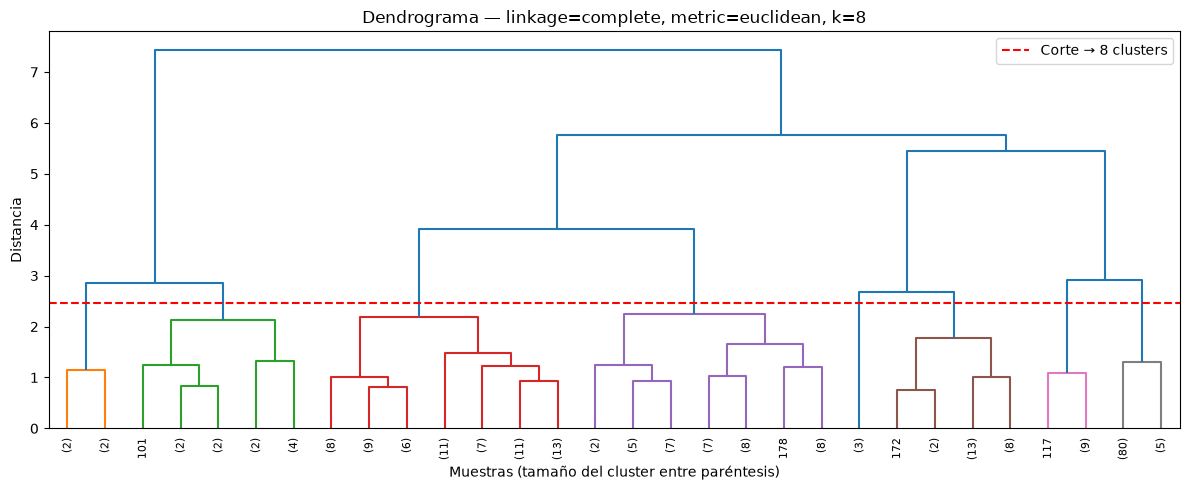

In [18]:
import scipy.cluster.hierarchy as sch
from scipy.cluster.hierarchy import dendrogram

# Construimos la linkage matrix con scipy (mismos parámetros que el modelo final)
Z = sch.linkage(datos_pca, method=mejor_lnk, metric=mejor_met)

# Calculamos la altura de corte entre la k-ésima y (k-1)-ésima última fusión
# eso, ha efectos prácticos, es lo mismo que encontrar el distance_treshold optimo para este problema
altura_corte = (Z[-mejor_k, 2] + Z[-(mejor_k - 1), 2]) / 2

fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(Z, truncate_mode='lastp', p=30,
           color_threshold=altura_corte,
           leaf_rotation=90, leaf_font_size=8, ax=ax)
ax.axhline(y=altura_corte, color='red', linestyle='--',
           label=f'Corte → {mejor_k} clusters')
ax.set_title(f'Dendrograma — linkage={mejor_lnk}, metric={mejor_met}, k={mejor_k}')
ax.set_xlabel('Muestras (tamaño del cluster entre paréntesis)')
ax.set_ylabel('Distancia')
ax.legend()
plt.tight_layout()
plt.show()

Este dendograma nos da resultados muy interesantes, pues en parte, a nuestro juicio, explica el por qué ha decidido que k sea 8 en vez de 6. Para nosotros, el modelo se ha dejado influenciar por estrellas extremadamente raras, como se puede apreciar al ver que hay clusters de tamaños muy distintos (clústers de 178 estrellas y otros de 2).

Esto ocurre porque el enlace "complete" calcula la distancia basándose en el par de observaciones más alejadas entre dos clústeres. En el caso de estas estrellas "anómalas" (como podrían ser las hipergigantes o enanas muy peculiares), su distancia al resto de datos es tan grande que el algoritmo penaliza fuertemente su inclusión en los clústeres mayoritarios. Por lo tanto, en lugar de forzarlas dentro de las 6 clases principales, la métrica de enlace decide "aislarlas" en pequeños grupos independientes para mantener la compacidad del resto. Así, el número de clústeres óptimo se eleva a 8, no porque existan 8 tipos de estrellas, sino porque el modelo ha preferido crear clústeres específicos para estas estrellas antes que arruinar la cohesión interna de las grandes agrupaciones de la secuencia principal o las enanas rojas.

## 3.3. DBSCAN

El próximo (y último) modelo a evaluar es el modelo DBSCAN, basado en densidad. En este modelo, se define un grupo si hay una región con una alta densidad de puntos. A diferencia de algoritmos como k-means, basados en centroides, en DBSCAN los clústers pueden ser de cualquier forma geométrica. Otras características de estos modelos es que no se requiere especificar el número de grupos que se van a hacer, el modelo lo determina automáticamente. Además, es muy robusto al ruido, ya que los outliers los deja sin clasificar directamente, evitando distorsionar los clústers por intentar incluirlas a la fuerza. 

En cuanto a sus hiperparámetros, tenemos:
- eps: Distancia máxima entre dos muestras para que una se considere vecina de la otra. Define el 𝜖-neighborhood
- min_samples: El número de muestras (o peso total) en un vecindario para que un punto se considere un core point. Esto incluye el propio punto. Si min_samples se establece en un valor más alto, DBSCAN encontrará conglomerados más densos, mientras que si se establece en un valor más bajo, los conglomerados encontrados serán más dispersos.
- metric: métrica utilizada como distancia. Puede ser: “euclidean”, “l1”, “l2”, “manhattan”, “cosine”, or “precomputed”. Por defecto es “euclidean”.

### 3.3.1. Métrica DBCV

La métrica DBCV es una métrica que mide compara la menor densidad dentro de un clúster con la mayor densidad en la frontera que lo separa de otro clúster. Podríamos decir que esta métrica es el equivalente al coeficiente de Silhouette en los algoritmos de densidad. Este último no se puede usar aquí ya que precisamente lo que hace es medir la distancia media de un punto al resto de los puntos de su mismo clúster y la compara con la distancia media a los puntos del clúster más cercano, premiando a los clústers con formas geométricas y compactas; y como precisamente DBSCAN no usa distancias, si no densidad, aquí silhouette no sería recomendable utilizar.

Como dice el enunciado, esta métrica no está en la librería de Scikit-learn, y tras buscar en internet, hemos llegado a la conclusión de que la mejor opción es usar la que viene en el tutorial de clustering que podemos encontrar en Aula Global. 


### 3.3.2. Entrenamiento y obtención del modelo

Para entrenar el modelo, comenzamos obteniendo los mejores hiperparámetros para nuestro caso en específico. Para comparar las combinaciones, usaremos la métrica instalada en la celda anterior.

**a) Encontrar eps de partida razonable** 

Para encontrar los mejores hiperparámetros, no maximizaremos DBCV a ciegas, ya que premia los clusters densos y muy separados, por lo que tiende a priorizar soluciones que colapsan todo en grupos muy grandes, incluso en solo dos clústers. De hecho, la primera vez que realizamos este apartado con esta métrica, nos pasó precisamente eso, obtuvimos una métrica de DBCV muy alta (0.83), pero solo dos clústers, por lo que a efectos prácticos no obteníamos información relevante. Para evitarlo, empezamos por obtener una eps de partida coherente con la naturaleza del problema, basándonos en cómo lo hace el tutorial suministrado.



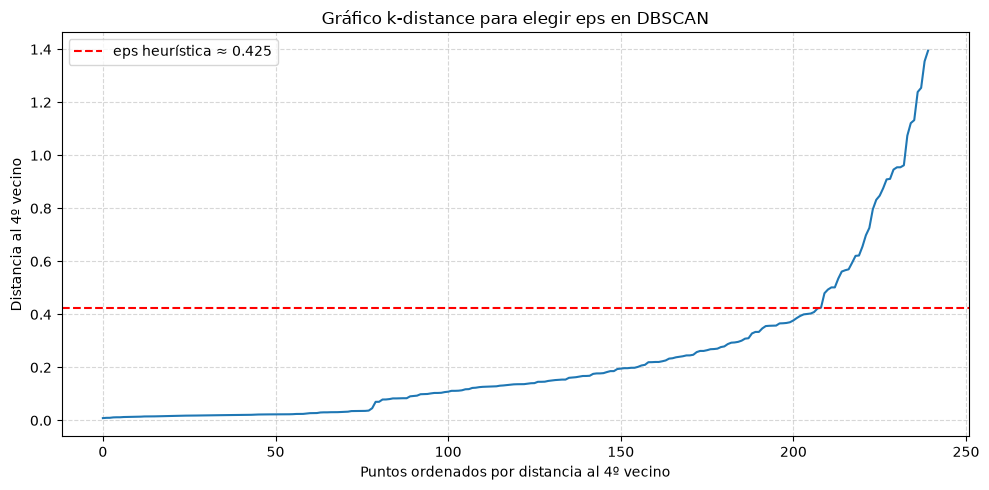

Eps de partida sugerida por la heurística: 0.425


In [19]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from dbcv import dbcv


min_samples_heur = 5
nn = NearestNeighbors(n_neighbors=min_samples_heur).fit(datos_pca)
distancias, _ = nn.kneighbors(datos_pca)
distancias_k = np.sort(distancias[:, -1])  # distancia al k-ésimo vecino, ordenada


# Importante: esta línea la hemos puesto nosotros tras evaluar el gráfico de forma visual, ajustando manualmente para 
# que la recta cortase justo donde nosotros considerabamos que cortaba.
eps_heur = np.percentile(distancias_k, 87)

plt.figure(figsize=(10, 5))
plt.plot(distancias_k)
plt.axhline(y=eps_heur, color='r', linestyle='--',
            label=f'eps heurística ≈ {eps_heur:.3f}')
plt.xlabel(f'Puntos ordenados por distancia al {min_samples_heur-1}º vecino')
plt.ylabel(f'Distancia al {min_samples_heur-1}º vecino')
plt.title('Gráfico k-distance para elegir eps en DBSCAN')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Eps de partida sugerida por la heurística: {eps_heur:.3f}")


Tras evaluar de forma visual la gráfica, hemos decidido que nuestra eps de partida tendrá el valor 0.425, ya que en nuestra opinión es aquí donde realmente se encuentra el "codo" de la gráfica.

**b) Búsqueda de los mejores hiperparámetros**

Una vez tenemos la eps de partida, procedemos a hacer el grid search para encontrar la mejor combinación de hiperparámetros para este problema. Para eso ejecutaremos los siguientes pasos:

1. Probaremos todas las combinaciones posibles que tengan sentido, ya que DBCV puede lanzar errores para combinaciones que den un resultado excesivamente bajo (combinaciones donde la mayoría es ruido)
2. Haremos un heatmap con los resultados de todas las combinaciones.
3. Seleccionaremos la mejor combinación de hiperparámetros.
4. Entrenaremos el modelo final.

Empezamos por los dos primeros pasos.

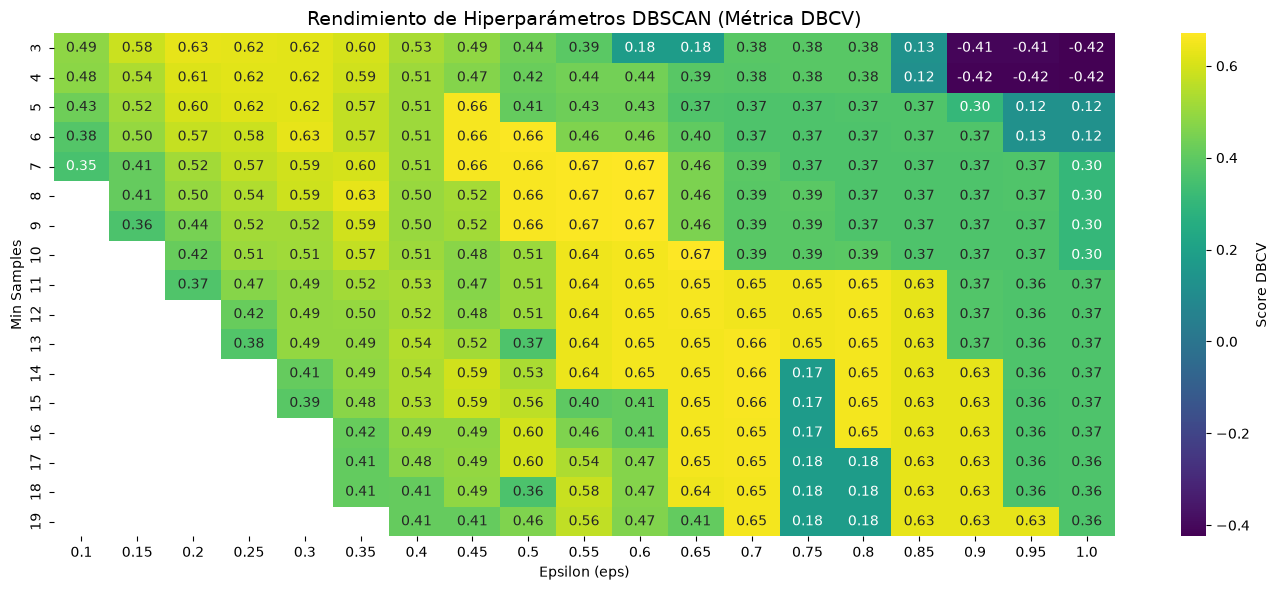

In [20]:

# Definimos el espacio de busqueda
rango_eps = np.arange(0.10, 1.01, 0.05)   # paso 0.05 (más fino que 0.1)
rango_min_samples = range(3, 20)           

resultados = [] # aquí se guardarán los resultados

# entrenamos cada combinacion
for eps in rango_eps:
    for ms in rango_min_samples:

        # Entreanmos el modelo con la combinacion actual
        modelo = DBSCAN(eps=eps, min_samples=ms)
        etiquetas = modelo.fit_predict(datos_pca)

        n_clusters = len(set(etiquetas)) - (1 if -1 in etiquetas else 0)
        n_ruido = int((etiquetas == -1).sum())
        perc_ruido = n_ruido / len(etiquetas) * 100

        # Si la combinacion es muy mala, lo guardamos directamente para evitar que haya errores al pasarlo a DBCV
        if n_clusters < 2:
            resultados.append({'eps': round(eps, 3), 'min_samples': ms,
                               'n_clusters': n_clusters,
                               'perc_ruido': perc_ruido, 'dbcv': np.nan})
            continue

        try:
            # Calculamos el score de DBCV para la combinacion actual
            score = dbcv(datos_pca, etiquetas, metric='euclidean')
            resultados.append({'eps': round(eps, 3), 'min_samples': ms,
                               'n_clusters': n_clusters,
                               'perc_ruido': perc_ruido, 'dbcv': score})
        except Exception:
            # en el improbable caso de que salte una excepcion
            resultados.append({'eps': round(eps, 3), 'min_samples': ms,
                               'n_clusters': n_clusters,
                               'perc_ruido': perc_ruido, 'dbcv': np.nan})
            
# Generamos el heatmap

df_res = pd.DataFrame(resultados)


matriz_dbcv = df_res.pivot(index='min_samples', columns='eps', values='dbcv')

plt.figure(figsize=(14, 6))
sns.heatmap(matriz_dbcv, annot=True, fmt=".2f", cmap="viridis",
            cbar_kws={'label': 'Score DBCV'})
plt.title("Rendimiento de Hiperparámetros DBSCAN (Métrica DBCV)", fontsize=14)
plt.xlabel("Epsilon (eps)")
plt.ylabel("Min Samples")
plt.tight_layout()
plt.show()

Tras ejecutar el código observamos que en la zona amarilla se encuentran las combinaciones más prometedoras, obteniendo un score de más o menos un 0.67 aproximadamente. Para quedarnos con los hiperparámetros definitivos, continuamos con la siguiente celda.

In [21]:


# Filtros: n_clusters >= 3 (no colapsar todo) y perc_ruido <= 25%
candidatos = df_res[(df_res['n_clusters'] >= 3) &
                    (df_res['perc_ruido'] <= 25)].dropna(subset=['dbcv'])

print(" TOP 5 SIN filtros (criterio simple max DBCV) ")
print(df_res.dropna(subset=['dbcv'])
            .sort_values('dbcv', ascending=False)
            .head(5).to_string(index=False))

print("\n TOP 5 CON filtros (n_clusters>=3, ruido<=25%) ")
print(candidatos.sort_values('dbcv', ascending=False)
                .head(5).to_string(index=False))

mejor = candidatos.sort_values('dbcv', ascending=False).iloc[0]
mejor_eps = float(mejor['eps'])
mejor_ms = int(mejor['min_samples'])

print(f"\n HIPERPARÁMETROS FINALES ELEGIDOS:")
print(f"    eps         = {mejor_eps}")
print(f"    min_samples = {mejor_ms}")
print(f"    n_clusters  = {int(mejor['n_clusters'])}")
print(f"    %ruido      = {mejor['perc_ruido']:.1f}%")
print(f"    DBCV        = {mejor['dbcv']:.4f}")

 TOP 5 SIN filtros (criterio simple max DBCV) 
 eps  min_samples  n_clusters  perc_ruido     dbcv
0.65           10           4    9.166667 0.670737
0.60            8           4   10.000000 0.667237
0.60            7           4   10.000000 0.667237
0.60            9           4   10.000000 0.667237
0.55            7           4   10.416667 0.665622

 TOP 5 CON filtros (n_clusters>=3, ruido<=25%) 
 eps  min_samples  n_clusters  perc_ruido     dbcv
0.65           10           4    9.166667 0.670737
0.60            7           4   10.000000 0.667237
0.60            8           4   10.000000 0.667237
0.60            9           4   10.000000 0.667237
0.55            9           4   10.416667 0.665622

 HIPERPARÁMETROS FINALES ELEGIDOS:
    eps         = 0.65
    min_samples = 10
    n_clusters  = 4
    %ruido      = 9.2%
    DBCV        = 0.6707


Al ver las tablas, vemos que son prácticamente iguales, lo que significa que DBSCAN no ha tenido que recurrir a agrupar todo en 2 clústeres gigantes o generar un 80% de ruido para obtener una buena puntuación matemática.

Si observamos los hiperparámetros finales elegidos, vemos que obtenemos un eps moderado de 0.65 y un min_samples de 10, lo que evita formar grupos muy pequeños de estrellas que formen micro-clústeres "falsos".

Para cargar el modelo final ejecutamos la celda siguiente:

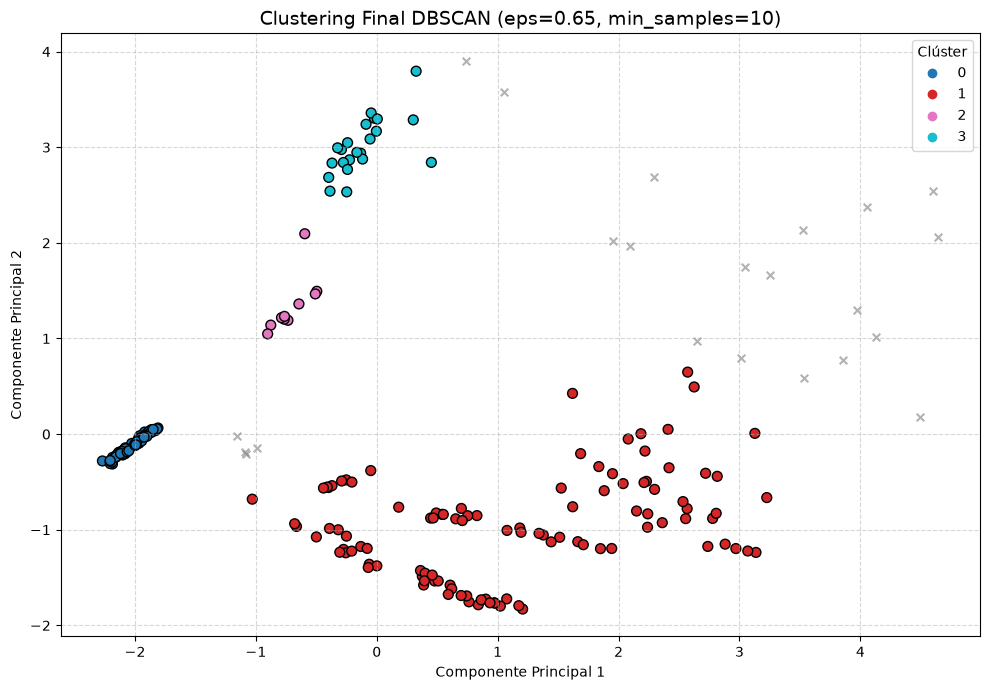

In [22]:

#entrenamos el modelo final con la mejor combinacion (la del apartado anterior)
modelo_final = DBSCAN(eps=mejor_eps, min_samples=mejor_ms)
etiquetas_finales = modelo_final.fit_predict(datos_pca)

# dibujamos la gráfica de las componentes
plt.figure(figsize=(10, 7))
ruido = etiquetas_finales == -1
plt.scatter(datos_pca[ruido, 0], datos_pca[ruido, 1],
            c='grey', marker='x', s=30, label='Ruido (-1)', alpha=0.6)
clusteres_validos = ~ruido
scatter = plt.scatter(datos_pca[clusteres_validos, 0],
                      datos_pca[clusteres_validos, 1],
                      c=etiquetas_finales[clusteres_validos],
                      cmap='tab10', s=50, edgecolor='k')
plt.title(f"Clustering Final DBSCAN (eps={mejor_eps}, min_samples={mejor_ms})",
          fontsize=14)
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend(*scatter.legend_elements(), title="Clúster", loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

La agrupación que ha hecho DBSCAN es reveladora y sobre todo muy distinta, lo que evidencia la diferencia de los algoritmos basados en densidad respecto al resto. Esto es así principalmente porque ha hecho solo 4 clústers, algo extraño (esperábamos seis más o menos), pero que si nos acordamos del Diagrama de Hertzsprung-Russell, cobra sentido. Este diagrama clasifica a las estrellas en seis grupos, sin embargo, si vemos en detalle como están dispuestos esos grupos vemos que tres de ellos son grupos diferenciados y separados de los demás (enanas blancas, gigantes y supergigantes), y otros tres grupos dispuestos en una fila continua, una secuencia principal. Pues bien, si vemos como ha agrupado el modelo, tenemos la misma forma, tres clusters arriba a la izquierda (0, 2 y 3), y un gran clúster 1, que probablemente represente la secuencia principal del diagrama mencionado anteriormente. 

Para nosotros, la razón por la que sospechamos que no ha conseguido distinguir los tres grupos dentro de la secuencia principal no tiene que ver con la naturaleza del modelo, sino con un paso previo anterior que hicimos, el PCA. Creemos esto porque al fin y al cabo, el modelo no ha trabajado sobre el dataset original con todas las variables originales, si no sobre la transformación resultante de hacer PCA de 2 componentes (cada uno siendo una combinación lineal de las variables originales) en el dataset. Por ello, es posible que la información necesaria para poder separar los grupos de la secuencia principal se perdiese al generar las componentes, de forma que DBSCAN no tiene forma real de poder identificar y separar esos grupos. Otra razón importante que puede explicar el resultado es la propia naturaleza del propio algoritmo: DBSCAN solo puede separar grupos si existe una frontera de baja densidad entre ellos. En la zona de la secuencia principal, las enanas marrones, enanas rojas y estrellas de secuencia principal forman un continuo denso sin esa frontera, por lo que DBSCAN los ve como una sola región y no puede diferenciarlos, sin importar qué hiperparámetros se usen.


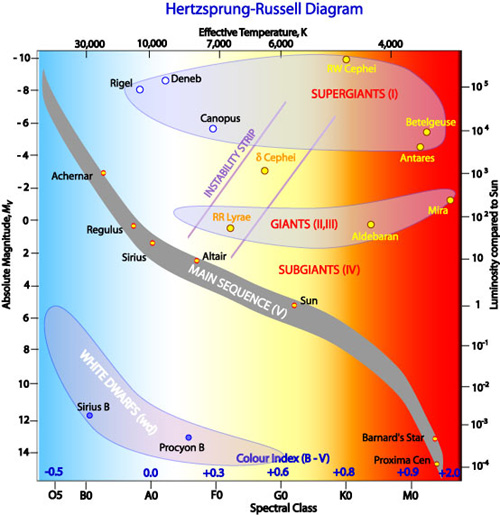

## 4. Modelo a utilizar

### 4.1. Modelo elegido: K-Means

Aunque nosotros teníamos dudas en cuanto a la selección del modelo final, ya que tanto el modelo de DBSCAN como el de k-Means nos parecían modelos que se habían comportado de forma más que correcta, el resultado de K-Means nos convenció más al final, sobre todo si comparamos los resultados con la tabla del enunciado.

Esto es así principalmente por la naturaleza de K-Means y de DBSCAN, el primero basado en distancias a centroides y el segundo en densidad, de forma que K-Means nos ha devuelto el mejor resultado con 6 clústers, y DBSCAN con 4. Además de forma visual, el resultado devuelto por K-Means es razonablemente más parecido al diagrama de HR que el de DBSCAN, ya que el resultado del último no consigue diferenciar bien los subgrupos de la secuencia principal, mientras que K-Means sí que lo hace. 

Por lo tanto, el motivo real de haber elegido K-Means por encima de DBSCAN es que a nivel visual el resultado del primero nos parece mejor (se asemeja más a la tabla). Nuestra decisión final no se basa en métricas ya que K-means y DBSCAN usan métricas distintas, el primero Silhouette y el segundo DBCV, por lo que no son comparables. De hecho, si lo fueran, probablemente habríamos elegido DBSCAN, ya que su DBCV es de 0.67, mientras que el Silhouette de K-Means es de 0.65, casi dos puntos menor.

Finalmente, descartamos el modelo basado en jerarquías ya que nos daba 8 clusters y un coeficiente de Silhouette más bajo que K-Means, por lo que no teníamos ningún argumento de peso real para elegirlo.

### 4.2. Pipeline a utilizar

Elegido el modelo, el pipeline que se debería usar, asumiendo que nos dan la tabla con los datos 'en bruto', sin haber sido tratada de ninguna forma, sería el siguiente:

1. Lo primero de todo, importaríamos la tabla (celda 1 del notebook).
2. Después, trataríamos las variables categóricas Color y Spectral_class, tratando los valores mal escritos en Color y convirtiéndolas de categóricas a ordinales. Para ello deberíamos ejecutar la celda 8.
3. A continuación, deberíamos escalar todas las instancias y hacer el PCA para sacar las dos componentes principales. Esto lo conseguiríamos ejecutando la décima y la undécima celda.
4. Una vez tuviésemos esto, ya nos quedaría por último entrenar el modelo final, K-Means con 6 clústers (con k= 6 obtuvimos el Silhouette más alto), por lo tanto, tendríamos que ejecutar la celda número 15. 

Una vez realizados todos estos pasos, obtendríamos el modelo final correctamente.

## 5. Comparación entre los resultados obtenidos y la tabla.

La tabla del enunciado nos indica que hay seis tipos de estrellas. El hecho de que obtengamos 6 clusters en el resultado el modelo es una buena señal. Para entender las similitudes (en caso de que las haya) es vital recordar el peso que tiene cada variable en las componentes principales producto de hacer el pca. En la componente 1 (el eje X), vemos que la Temperatura, la Luminosidad y las variables categóricas tienen pesos positivos fuertes, mientras que la Magnitud Absoluta (A_M) resta. Esto significa que las estrellas situadas más hacia la derecha son las más calientes, luminosas y brillantes. Por otro lado, en la componente 2 (el eje Y), el peso dominante es el Radio (0.637), mientras que la Temperatura resta (-0.218). Por tanto, los valores altos en el eje Y indican estrellas de tamaño grande, y los valores negativos indican estrellas con radios pequeños pero temperaturas muy altas.

Con esto, y comprobando las medias y rangos de temperatura, luminosidad, radio y magnitud de cada cluster, los grupos que ha encontrado K-Means son los siguientes:

- **Hipergigantes (cluster 4, 24 estrellas, arriba al centro):** radios enormes (entre 955 y 1673 veces el del Sol), que son los más grandes del dataset. Al tener el Radio el peso positivo más alto en la componente 2, esta variable los dispara hacia la parte más alta del gráfico.
- **Supergigantes calientes (cluster 1, 18 estrellas, centro-derecha):** muy luminosas y de temperaturas altas, lo que las empuja fuertemente hacia la derecha en el eje X. Su radio es grande, pero menor de media que el de las hipergigantes, y por eso se quedan un escalón por debajo en el eje Y.
- **Gigantes rojas (cluster 0, 10 estrellas, arriba a la izquierda):** son frías (entre 3000 y 3800 K, por lo que quedan a la izquierda) pero muy luminosas y de radio grande, lo que las sube en el eje Y. Son un grupo pequeño que K-Means separa de las otras gigantes por su baja temperatura.
- **Secuencia principal caliente (cluster 5, 42 estrellas, abajo a la derecha):** son muy calientes y luminosas (derecha en el eje X), pero con radio moderado. Al tener mucha temperatura (que resta en el eje Y) y menos radio, caen hacia la parte negativa de la componente 2.
- **Enanas blancas y secuencia principal tenue (cluster 2, 61 estrellas, abajo en el centro):** tienen temperaturas medias-altas, pero luminosidad y radio muy pequeños. Es el grupo con el valor más negativo en el eje Y. Por su tamaño (61 estrellas) y su rango de magnitudes, pensamos que junta a las enanas blancas con las estrellas de secuencia principal menos luminosas.
- **Enanas rojas y marrones (cluster 3, 85 estrellas, extremo izquierdo):** tienen la luminosidad, el radio y la temperatura más bajos, y la Magnitud Absoluta más alta. Esa magnitud tan grande, multiplicada por el peso negativo de la componente 1, hunde a estas estrellas en el extremo izquierdo del gráfico.

**Conclusión de la comparación:** K-Means recupera bien los grandes grupos de la tabla (enanas frías, enanas blancas, secuencia principal y gigantes), pero **no coincide uno a uno con las seis clases**. El caso más claro es el de las enanas rojas y las enanas marrones: las 40 estrellas con magnitud absoluta mayor o igual que 16 (las más tenues del dataset, típicas de las enanas marrones) caen todas en el cluster 3 junto con las enanas rojas, por lo que el modelo no las separa. El sexto cluster se emplea en cambio para subdividir las gigantes (clusters 0, 1 y 4). Creemos que esto se debe a que las enanas rojas y marrones tienen valores muy parecidos en las seis variables y, al reducir a dos componentes con el PCA, se pierde parte de lo que podría distinguirlas.

Para ver de forma visual estas agrupaciones, volvemos a graficar el resultado de k-means, pero esta vez con los nombres de los grupos:

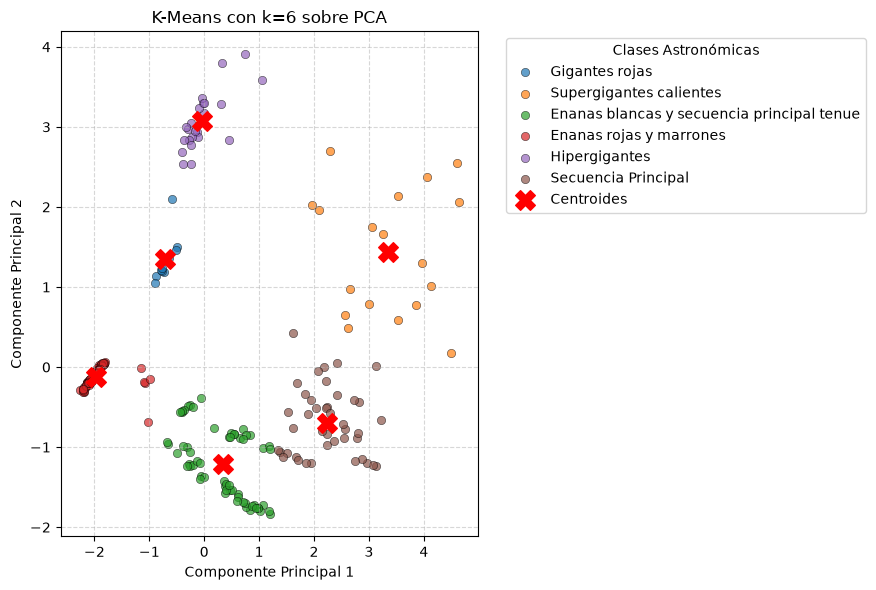

Silueta final (k=6): 0.6517
Inercia final (k=6): 84.60


In [23]:
# Modelo final con el k óptimo
kmeans_final = KMeans(n_clusters=6, random_state=100522281, n_init=20)
kmeans_final.fit(datos_pca)
labels = kmeans_final.labels_

# Diccionario para mapear cada cluster a su clase astronómica
nombres_clases = {
    0: 'Gigantes rojas',
    1: 'Supergigantes calientes',
    2: 'Enanas blancas y secuencia principal tenue',
    3: 'Enanas rojas y marrones',
    4: 'Hipergigantes',
    5: 'Secuencia Principal'
}


# Creamos la grafica

plt.figure(figsize=(9, 6))

# Obtenemos el mismo mapa de colores que usabas para mantener la coherencia
cmap = plt.cm.tab10 

# Pintamos cada cluster por separado para poder asignarle su nombre en la leyenda
for cluster_num in range(6):
    idx = labels == cluster_num
    plt.scatter(datos_pca[idx, 0], datos_pca[idx, 1], 
                color=cmap(cluster_num), alpha=0.7, edgecolors='k', 
                linewidths=0.4, label=nombres_clases[cluster_num])

# Añadimos los centroides
plt.scatter(kmeans_final.cluster_centers_[:, 0], kmeans_final.cluster_centers_[:, 1],
            c='red', marker='X', s=200, label='Centroides', zorder=5)

plt.title('K-Means con k=6 sobre PCA')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')

# Colocamos la leyenda fuera del gráfico para que no tape los puntos
plt.legend(title='Clases Astronómicas', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout() # Ajusta los márgenes para que quepa la leyenda exterior
plt.show()

# Métricas
from sklearn.metrics import silhouette_score
print(f"Silueta final (k=6): {silhouette_score(datos_pca, labels):.4f}")
print(f"Inercia final (k=6): {kmeans_final.inertia_:.2f}")